# Primer decoder conductual: PCA y Hamiltoniano cuadratico

Pregunta de esta prueba: ¿una funcion compartida de las representaciones acumuladas
permite estimar la etiqueta final manual de RH en rollouts no usados para ajustarla?

Se usan los 72 rollouts clasificados por Nahuel (51 RH y 21 no RH). Los 28 X
quedan fuera del encoder, del ajuste supervisado y de la evaluacion. r0001 (RH)
y r0026 (no RH, EOS) son los dos ejemplos de referencia elegidos por el revisor.

Esta prueba observa prefijos de la respuesta; no constituye una prediccion
anterior a generar ni una medicion de la primera aparicion de RH. No se entrenan
pesos de la LLM, SAE ni mecanismos de steering. La etiqueta es la revision
operacional de Nahuel, incluido su criterio de corte incoherente por LOT.

## Notacion y protocolo fijo

$$\vec a_{\ell j}=\frac{1}{T+j}\sum_{t=0}^{T+j-1}\vec h_{\ell tj},\qquad T=61.$$

$$\xi_{ij}^{(\ell)}=\langle\vec v_i^{(\ell)},\vec a_{\ell j}-\vec\mu_\ell\rangle,
\qquad \Xi_{ij\ell}=\xi_{ij}^{(\ell)}.$$

Se mantienen 36 capas y se toma **K=1 por capa** en esta primera prueba.
Los pasos j son 0, 32, 64, 128 y 192. Todos los rollouts contienen al menos
192 tokens de contenido, por lo que no se usa relleno ni se incorporan EOS
para alcanzar esos horizontes. No se inspeccionan tokens posteriores a j
para construir el estado de ese paso. Las bases y el centro se mantienen fijos
a lo largo de cada trayectoria, y se ajustan solo con entrenamiento.

Fijando j, se aplana Xi en el orden direccion-capa para obtener x_j de 36
componentes. El decoder usa los **mismos parametros en todos los j**:

$$s_j=b_0+\vec g^{\top}\vec x_j+\frac12\vec x_j^{\top}H\vec x_j,
\qquad \widehat P(Y=1\mid\Xi_j)=\frac{1}{1+\exp(-s_j)}.$$

La regresion logistica usa penalizacion L2. El cuadratico completo tiene
703 parametros contando el intercepto, frente a 72 respuestas independientes.
El numero de prefijos no aumenta el numero de rollouts independientes.
La regularizacion es necesaria y los coeficientes no son identificados como
propiedades intrinsecas del modelo. No se calcula D_stat.

Se comparan prevalencia constante, lectura lineal, cuadratica diagonal y
cuadratica completa. Se usa validacion externa estratificada de tres folds;
la regularizacion se elige en otros tres folds internos. Un rollout completo
pertenece a un solo lado de cada particion. PCA y normalizacion se reajustan
dentro de cada entrenamiento interno: no ven los rollouts de validacion.
El horizonte principal fijado para esta prueba es j=192; se muestran los demas
sin seleccionar retrospectivamente el mejor.

In [ ]:
from pathlib import Path
import json
import sys

RAIZ = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'scripts/glossary_decoder.py').exists()), None)
if RAIZ is None:
    raise FileNotFoundError('Abra el notebook dentro del workspace o indique RAIZ.')
sys.path.insert(0, str(RAIZ / 'scripts'))
from glossary_decoder import cumulative_states, evaluate, figures, STEPS
SALIDA = RAIZ / 'analysis/glossary/decoder_v1'
SALIDA.mkdir(exist_ok=True)
print('Pasos j:', STEPS)
print('Sin cargar la LLM; calculo CPU sobre archivos de activaciones.')

Pasos j: (0, 32, 64, 128, 192)
Sin cargar la LLM; calculo CPU sobre archivos de activaciones.


In [ ]:
raw, labels, records = cumulative_states(RAIZ, SALIDA)
print('a_lj almacenado como [rollout,j,ell,componente]:', raw.shape)
print('j=0 es identico en todos los rollouts.')

Cumulative states: 10/100; RSS 0.18 GiB
Cumulative states: 20/100; RSS 0.21 GiB
Cumulative states: 30/100; RSS 0.24 GiB
Cumulative states: 40/100; RSS 0.26 GiB
Cumulative states: 50/100; RSS 0.29 GiB
Cumulative states: 60/100; RSS 0.32 GiB
Cumulative states: 70/100; RSS 0.34 GiB
Cumulative states: 80/100; RSS 0.37 GiB
Cumulative states: 90/100; RSS 0.40 GiB
Cumulative states: 100/100; RSS 0.43 GiB
a_lj almacenado como [rollout,j,ell,componente]: (100, 5, 36, 4096)
j=0 es identico en todos los rollouts.


In [ ]:
resultado = evaluate(raw, labels, records, SALIDA)
print('\nEVALUACION OUT-OF-FOLD')
print(f'\n{"Modelo":12} {"j":>4} {"AUROC":>8} {"Brier":>8} {"LogLoss":>8} {"BalAcc":>8}')
for fila in resultado['metrics']:
    print(f"{fila['model']:12} {fila['j']:4} {fila['AUROC']:8.3f} {fila['Brier']:8.3f} "
          f"{fila['log_loss']:8.3f} {fila['balanced_accuracy']:8.3f}")
print('\nMODELO FINAL, NO ES EVALUACION:')
print(json.dumps(resultado['summary'], indent=2))

Outer fold 1/3: 48 training, 24 test rollouts
Outer fold 2/3: 48 training, 24 test rollouts
Outer fold 3/3: 48 training, 24 test rollouts
Fitting final models on all 72 classified rollouts; these are not held-out scores.

EVALUACION OUT-OF-FOLD

Modelo          j    AUROC    Brier  LogLoss   BalAcc
constant        0    0.500    0.207    0.604    0.500
constant       32    0.500    0.207    0.604    0.500
constant       64    0.500    0.207    0.604    0.500
constant      128    0.500    0.207    0.604    0.500
constant      192    0.500    0.207    0.604    0.500
linear          0    0.500    0.207    0.605    0.500
linear         32    0.535    0.211    0.628    0.500
linear         64    0.581    0.206    0.609    0.500
linear        128    0.627    0.196    0.576    0.514
linear        192    0.629    0.200    0.578    0.490
diagonal        0    0.500    0.207    0.604    0.500
diagonal       32    0.507    0.209    0.610    0.500
diagonal       64    0.577    0.206    0.607    0.50

## Lectura de resultados y figuras

AUROC mide la ordenacion entre positivos y negativos (0.5 como referencia sin
discriminacion). Brier y log-loss miden el error probabilistico; menor es mejor.
La exactitud balanceada promedia la sensibilidad de ambas clases con umbral 0.5.
El baseline constante es la prevalencia del entrenamiento, no una probabilidad
ajustada sobre el test. Las comparaciones son sobre los mismos folds externos.

Las curvas de r0001 y r0026 usan sus predicciones **fuera de entrenamiento**.
Cada par de curvas comparte un decoder entre pasos, pero los dos casos pueden
haber quedado en folds externos distintos. La evaluacion de grupo es por
rollout; las cinco mediciones de uno no son cinco observaciones independientes.

El H mostrado es el ajuste final con las 72 respuestas, en coordenadas PCA
estandarizadas. No se debe interpretar como evidencia causal ni como importancia
estable de capas: depende de PCA, escalado, regularizacion y muestra.

In [ ]:
rutas_figuras = figures(resultado, SALIDA)
print('\n'.join(str(p) for p in rutas_figuras))

.\output\analisis_glosario_100\decoder_v1\01_reference_cases_oof.png
.\output\analisis_glosario_100\decoder_v1\02_evaluation_oof.png
.\output\analisis_glosario_100\decoder_v1\03_final_H_and_encoder.png


## Parametros y reproduccion del score

`encoder_PCA.npz` guarda centros, direcciones, varianza retenida y escalado.
`Xi_final.npy` tiene ejes [rollout,i,j,ell] y dimensiones (100,1,5,36).
Las coordenadas finales fueron aprendidas con los 72 rollouts etiquetados;
no son las coordenadas de cada fold de evaluacion.

`decoder_quadratic.npz` contiene b0, g y H en las coordenadas PCA originales
y tambien sus versiones estandarizadas. El codigo verifica que reconstruyen
los logits del predictor. Los terminos diagonales de H llevan el factor dos
correspondiente a la convencion 1/2 x^T H x.

Los parametros finales se ajustan sobre todas las etiquetas disponibles.
`predictions_oof.csv` es el archivo valido para evaluar capacidad predictiva;
`predictions_final_in_sample_or_X.csv` contiene ajustes finales y predicciones
exploratorias para X, sin convertirlas en etiquetas.

La captura original no se modifica. `a_lj.npy` es una cache de unos 281 MiB;
el resto del calculo conserva solo resumentes, coordenadas, coeficientes y figuras.

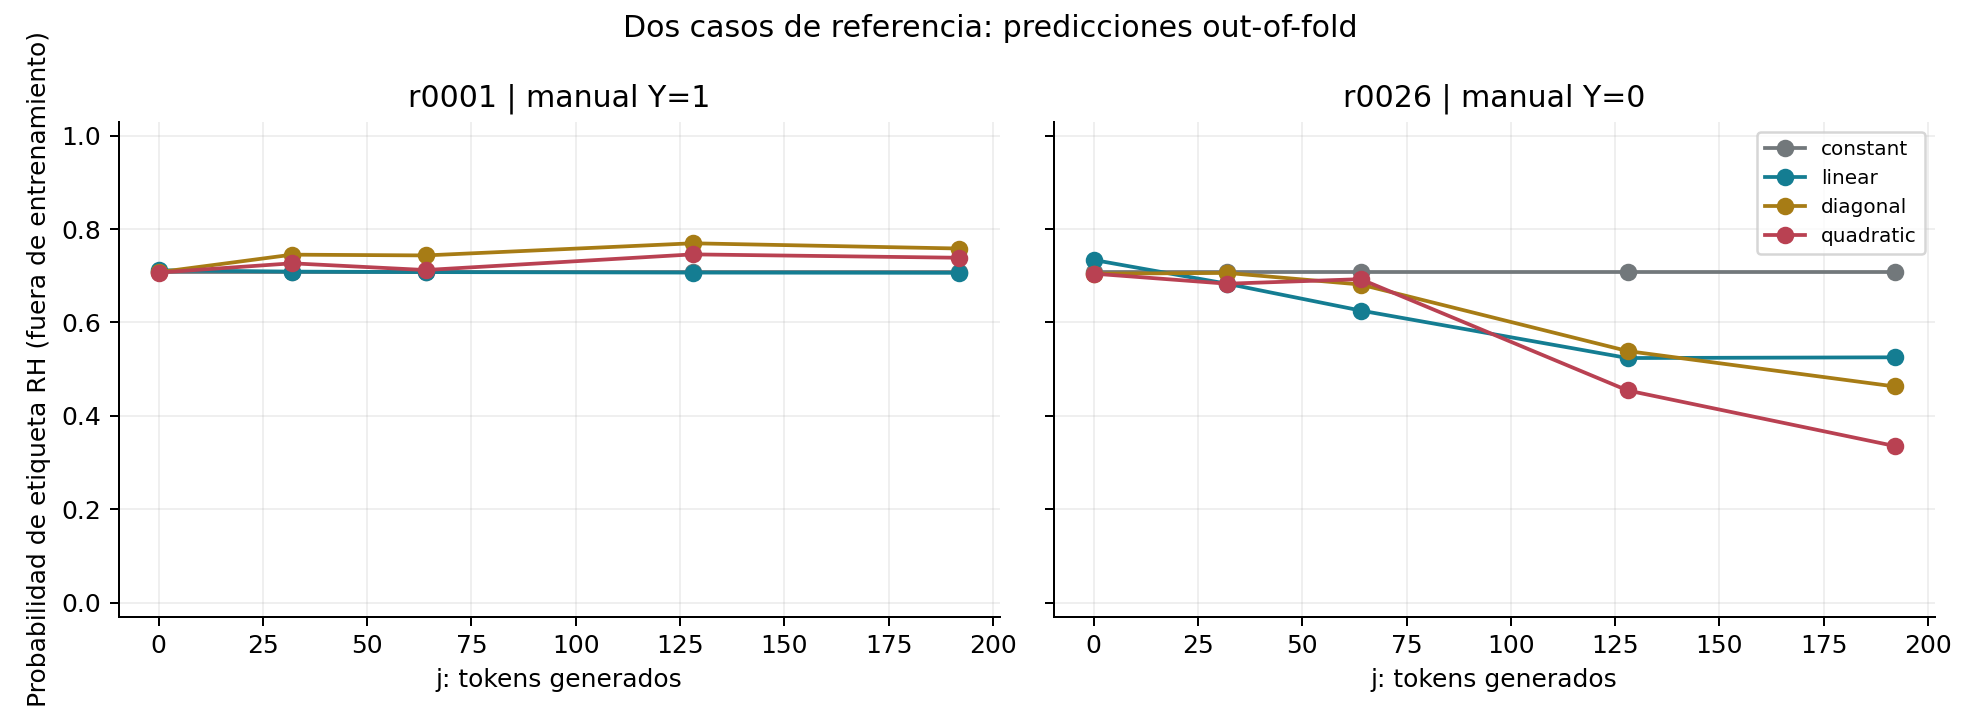

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(SALIDA / '01_reference_cases_oof.png')))

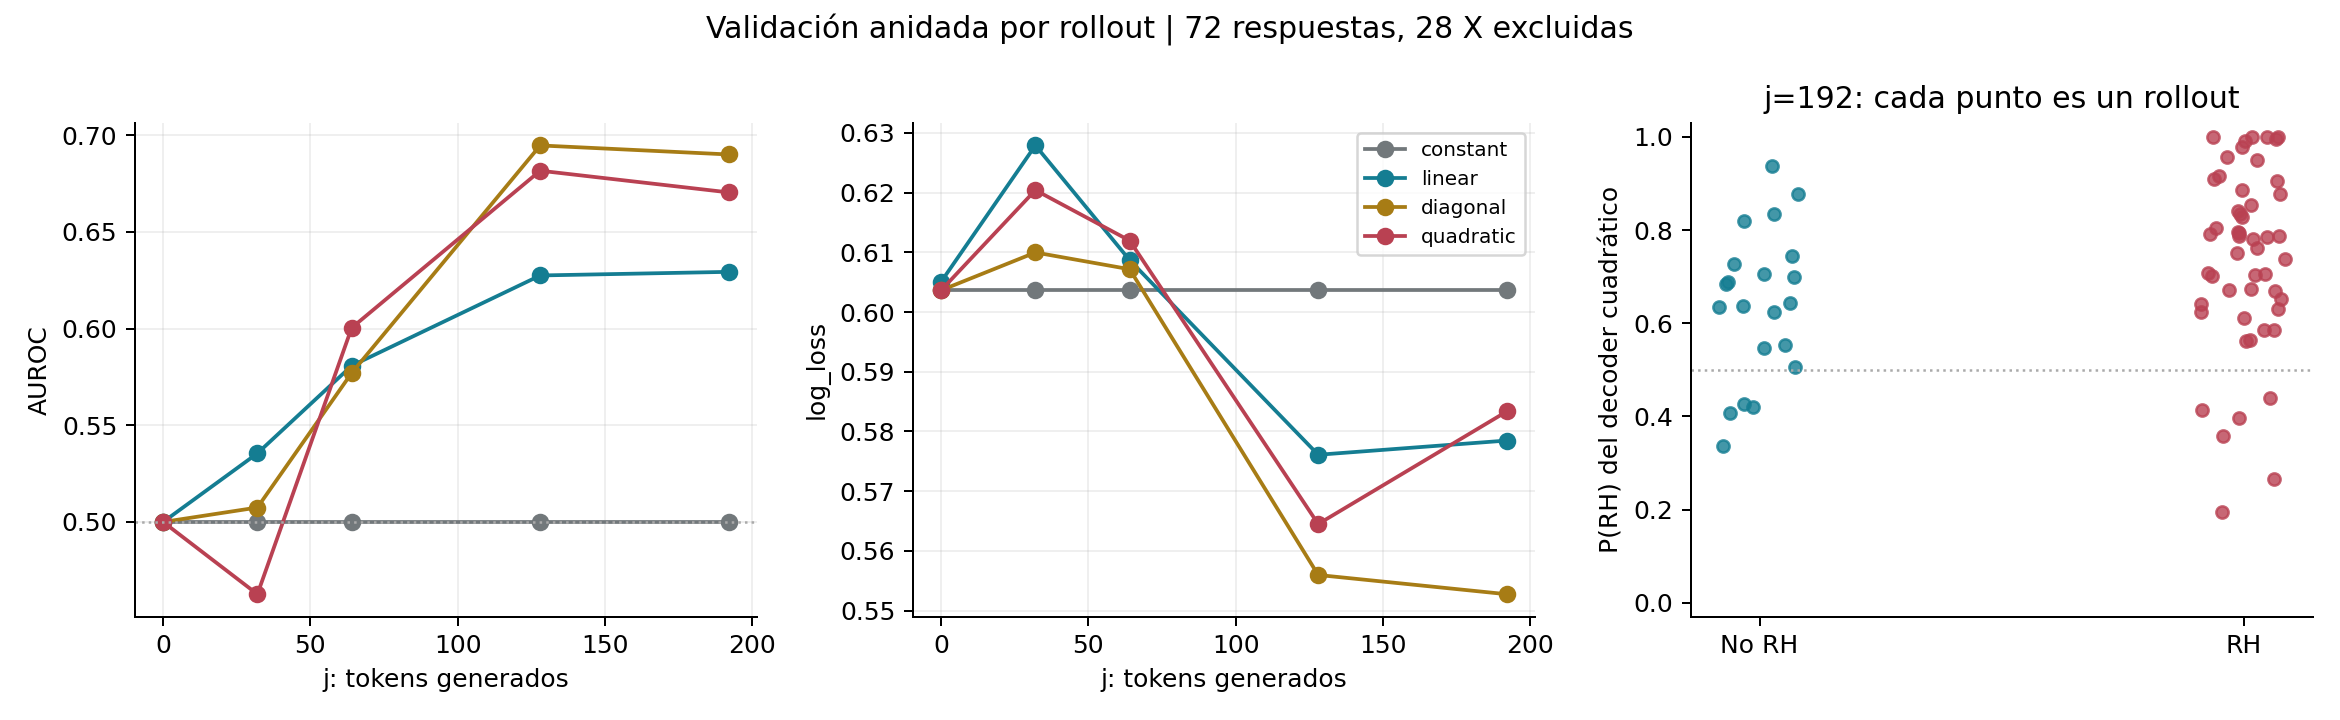

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(SALIDA / '02_evaluation_oof.png')))

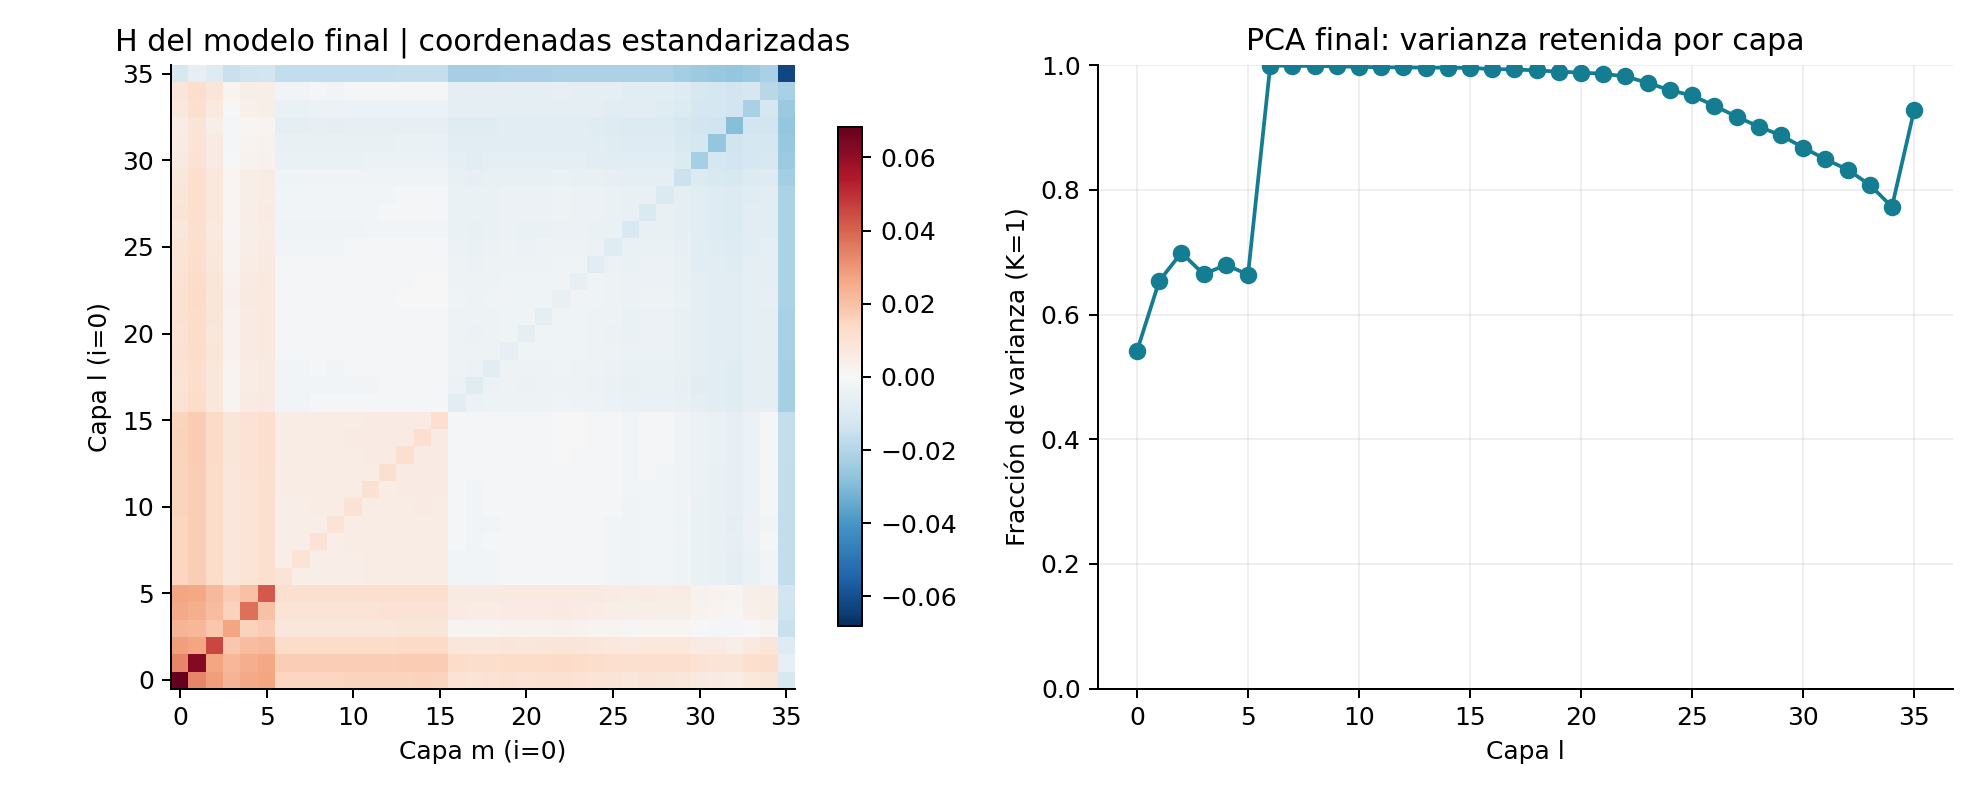

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(SALIDA / '03_final_H_and_encoder.png')))